# Start

In [318]:
from pyprojroot import here
import polars as pl
import cv2
import numpy as np
from typing import Literal
import matplotlib.pyplot as plt
import seaborn as sns
import os
from skimage.filters import frangi

In [2]:
# params
path_data = here() / "data"
path_processed = path_data / "processed"
path_raw = path_data / "raw"
path_raw_img = path_raw / "Images"
path_sample_img = path_raw_img / "31_2.jpg"
path_crop_out = path_processed / "od_images"

size_preview = (500, 500)

seed = 123

In [3]:
df = pl.read_csv(path_processed / "labels.csv")
df.head()

Image Name,Patient,Label,Quality Score,SPLIT,Height,Width
str,i64,str,f64,str,i64,i64
"""0_0.jpg""",0,"""GON+""",6.18,"""TRAIN""",1918,1918
"""1_0.jpg""",1,"""GON+""",5.31,"""TRAIN""",1929,1929
"""1_1.jpg""",1,"""GON+""",4.37,"""TRAIN""",1940,1940
"""2_0.jpg""",2,"""GON+""",3.51,"""TRAIN""",1893,1893
"""2_1.jpg""",2,"""GON+""",4.24,"""TRAIN""",1900,1900


# Tools

In [9]:
def imshow(input) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    cv2.imshow("Preview window", _img_resize)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [10]:
def imshow_c(input, channel: Literal["B", "G", "R"]) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    _img_channel = _img_resize[:, :, {"B": 0, "G": 1, "R": 2}[channel]]
    cv2.imshow("Preview window", _img_channel)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [11]:
def imshow_2(in1:np.ndarray, in2:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [12]:
def imshow_3(in1:np.ndarray, in2:np.ndarray, in3:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _in3_resize = cv2.resize(in3, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize, _in3_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [13]:
def mark(img, max_loc, crop_ratio=0.3):
    out = img.copy()
    h, w = out.shape[:2]

    crop_w = int(w * crop_ratio)
    crop_h = int(h * crop_ratio)

    x1 = max(max_loc[0] - crop_w // 2, 0)
    y1 = max(max_loc[1] - crop_h // 2, 0)
    x2 = min(max_loc[0] + crop_w // 2, w)
    y2 = min(max_loc[1] + crop_h // 2, h)

    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 10)
    cv2.drawMarker(out, max_loc, (0, 0, 255), cv2.MARKER_CROSS, 100, 15)

    return out

# OD - Brightest red spot

In [36]:
# Params
# img_file_name = "226_0"  # set to none for random
img_file_name = None

kernel_clean_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)) # remove random pixel
kernel_erode_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51)) # erode fov region to avoid halo
erode_iter = 10
fov_thres_val = 20

gaussian_blur_kernel: tuple = (71, 71)

crop_ratio = 0.3
crop_resize = 512

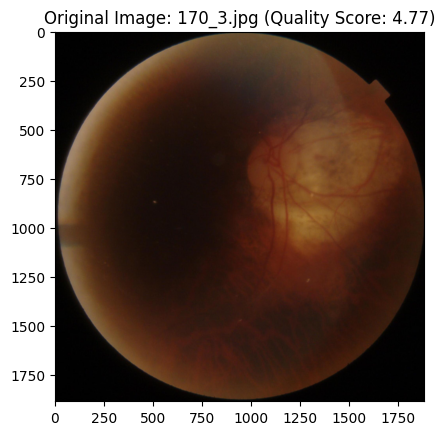

In [37]:
# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

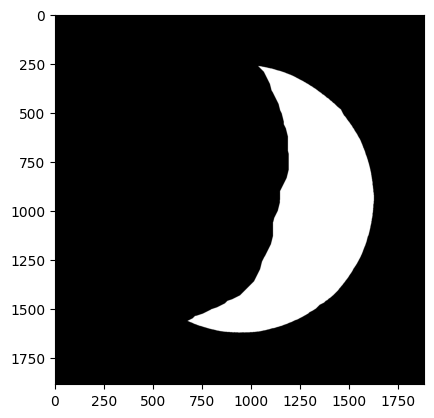

In [38]:
# get fov mask
img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
_, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)

# clean fov mask
fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

plt.imshow(fov_mask, cmap="gray")

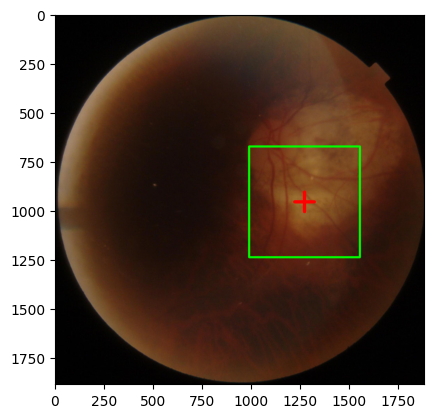

In [50]:
# find brightest spot
img_red = img_ori[:, :, 2]
img_blur = cv2.GaussianBlur(img_red, gaussian_blur_kernel, 0)
masked_img = cv2.bitwise_and(img_blur, img_blur, mask=fov_mask)
_, _, _, max_loc = cv2.minMaxLoc(masked_img)

# show marked spot
plt.imshow(cv2.cvtColor(mark(img_ori, max_loc, 0.3), cv2.COLOR_BGR2RGB))

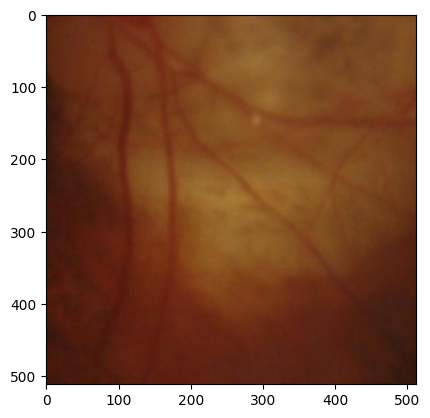

In [51]:
# cropping
crop_width = int(sample_width * crop_ratio)
crop_height = int(sample_height * crop_ratio)

x1 = max(max_loc[0] - crop_width // 2, 0)
y1 = max(max_loc[1] - crop_height // 2, 0)
x2 = min(max_loc[0] + crop_width // 2, sample_width)
y2 = min(max_loc[1] + crop_height // 2, sample_height)

cropped_img = img_ori[y1:y2, x1:x2]
cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))
plt.imshow(cv2.cvtColor(cropped_resize_img, cv2.COLOR_BGR2RGB))

# OD - Geometry

In [411]:
# Params
# img_file_name = "0_0"  # set to none for random
img_file_name = None

kernel_clean_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)) # remove random pixel
kernel_erode_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51)) # erode fov region to avoid halo
erode_iter = 10
fov_thres_val = 20

sobel_ksize = 7
gaussian_blur_kernel: tuple = (51, 51)

crop_ratio = 0.3
crop_resize = 512

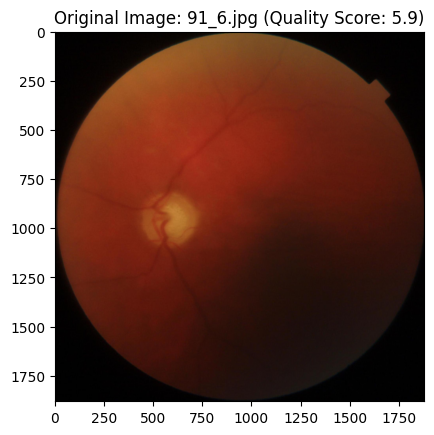

In [189]:
# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

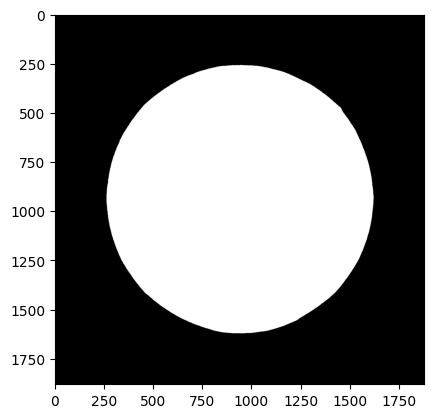

In [413]:
# get fov mask
img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
_, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)

# clean fov mask
fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

plt.imshow(fov_mask, cmap="gray")

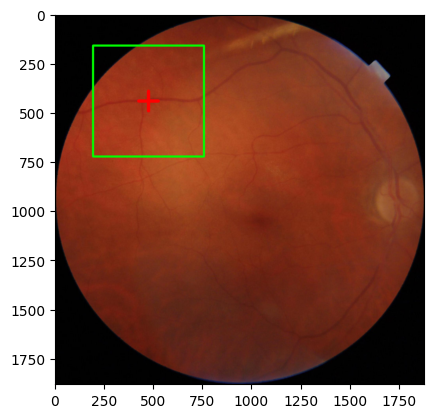

In [414]:
gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
grad = cv2.magnitude(
    cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=sobel_ksize),
    cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=sobel_ksize),
)
grad_blur = cv2.GaussianBlur(np.abs(grad), gaussian_blur_kernel, 0)
_, _, _, loc_texture = cv2.minMaxLoc(
    cv2.bitwise_and(np.abs(grad_blur), np.abs(grad_blur), mask=fov_mask)
)

plt.imshow(cv2.cvtColor(mark(img_ori, loc_texture, crop_ratio=0.3), cv2.COLOR_BGR2RGB))
# plt.imshow(grad_blur, cmap="gray")

# OD Vessel

In [394]:
# Params
# img_file_name = "0_0"  # set to none for random
img_file_name = None

kernel_erode_fov_mask = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (101, 101)
)  # erode fov region to avoid halo
erode_iter = 1
fov_thres_val = 20

sobel_ksize = 7
gaussian_blur_kernel: tuple = (51, 51)

crop_ratio = 0.3
crop_resize = 512

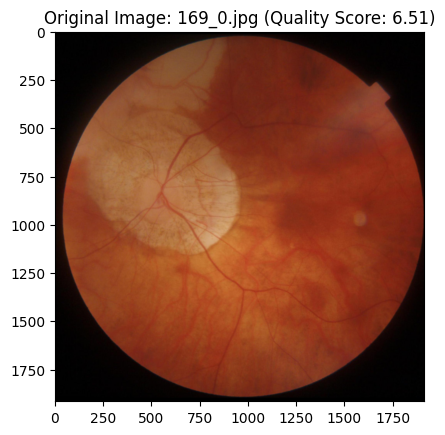

In [423]:
# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

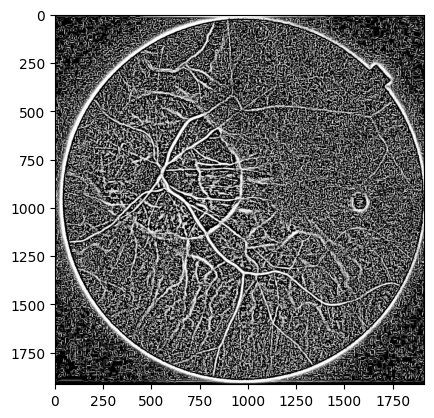

In [424]:
green = img_ori[:, :, 1]

vessels = frangi(
    green,
    sigmas=range(2, 30, 4),  # Start at 2 to skip pixel noise, go up to 30
    alpha=0.7,  # Be stricter about 'line' vs 'blob'
    beta=0.5,
    gamma=0.05,  # Suppress faint retinal texture
    black_ridges=True,  # Vessels are dark on a bright background
) 
plt.imshow(vessels, cmap="gray")

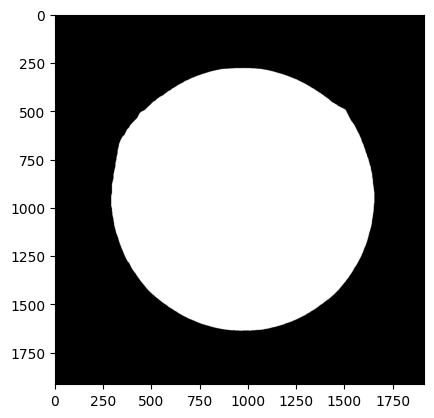

In [425]:
# get fov mask
img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
_, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)

# clean fov mask
fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

plt.imshow(fov_mask, cmap="gray")

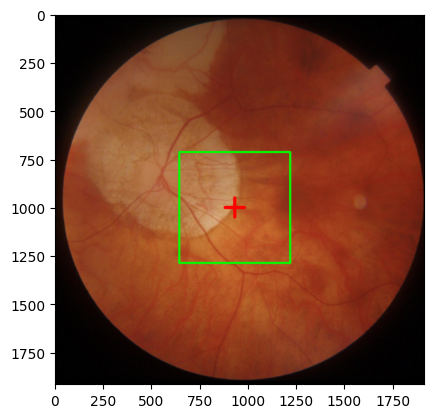

In [426]:
vessels_img = cv2.normalize(vessels, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
vessel_density = cv2.GaussianBlur(vessels_img, gaussian_blur_kernel, 0)
masked_vessels = cv2.bitwise_and(vessel_density, vessel_density, mask=fov_mask)
_, _, _, loc_vessels = cv2.minMaxLoc(masked_vessels)

plt.imshow(cv2.cvtColor(mark(img_ori, loc_vessels, crop_ratio=0.3), cv2.COLOR_BGR2RGB))
# plt.imshow(masked_vessels, cmap="gray")

# OD Batch crop

In [436]:
def crop_od(img, max_loc, crop_ratio=0.3):
    img_ori = img.copy()

    crop_resize = 512
    sample_height = img_ori.shape[0]
    sample_width = img_ori.shape[1]

    # cropping
    crop_width = int(sample_width * crop_ratio)
    crop_height = int(sample_height * crop_ratio)
    
    x1 = max(max_loc[0] - crop_width // 2, 0)
    y1 = max(max_loc[1] - crop_height // 2, 0)
    x2 = min(max_loc[0] + crop_width // 2, sample_width)
    y2 = min(max_loc[1] + crop_height // 2, sample_height)

    cropped_img = img_ori[y1:y2, x1:x2]
    cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))

    return cropped_resize_img

In [437]:
def od_bright(img):
    img_ori = img.copy()

    kernel_clean_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (15, 15)
    )  # remove random pixel
    kernel_erode_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (51, 51)
    )  # erode fov region to avoid halo
    erode_iter = 10
    fov_thres_val = 20
    gaussian_blur_kernel: tuple = (71, 71)

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

    # find brightest spot
    img_red = img_ori[:, :, 2]
    img_blur = cv2.GaussianBlur(img_red, gaussian_blur_kernel, 0)
    masked_img = cv2.bitwise_and(img_blur, img_blur, mask=fov_mask)
    _, _, _, max_loc = cv2.minMaxLoc(masked_img)
    return max_loc

In [438]:
def od_sobel(img):
    img_ori = img.copy()

    kernel_clean_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (15, 15)
    )  # remove random pixel
    kernel_erode_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (51, 51)
    )  # erode fov region to avoid halo
    erode_iter = 10
    fov_thres_val = 20

    sobel_ksize = 7
    gaussian_blur_kernel: tuple = (51, 51)

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

    # sobel detection
    gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    grad = cv2.magnitude(
        cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=sobel_ksize),
        cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=sobel_ksize),
    )
    grad_blur = cv2.GaussianBlur(np.abs(grad), gaussian_blur_kernel, 0)
    _, _, _, loc_texture = cv2.minMaxLoc(
        cv2.bitwise_and(np.abs(grad_blur), np.abs(grad_blur), mask=fov_mask)
    )
    return loc_texture

In [439]:
def od_vessel(img):
    img_ori = img.copy()
    kernel_erode_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (101, 101))
    erode_iter = 1
    fov_thres_val = 20

    gaussian_blur_kernel: tuple = (51, 51)
    green = img_ori[:, :, 1]

    vessels = frangi(
        green,
        sigmas=range(2, 30, 4),
        alpha=0.7,
        beta=0.5,
        gamma=0.05,
        black_ridges=True,
    )

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)

    # clean fov mask
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)
    vessels_img = cv2.normalize(vessels, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    vessel_density = cv2.GaussianBlur(vessels_img, gaussian_blur_kernel, 0)
    masked_vessels = cv2.bitwise_and(vessel_density, vessel_density, mask=fov_mask)
    _, _, _, loc_vessels = cv2.minMaxLoc(masked_vessels)

    return loc_vessels

In [440]:
import random

img_ls = df.select("Image Name").to_numpy().flatten().tolist()
i = random.sample(img_ls, 1)[0]
img_path = path_raw_img / i

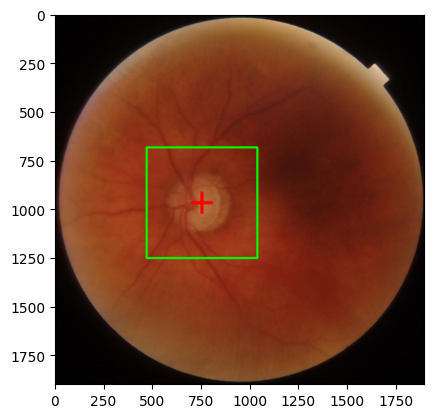

In [441]:
_maxloc = od_bright(cv2.imread(img_path))
cropped_img = crop_od(cv2.imread(img_path), _maxloc)
plt.imshow(
    cv2.cvtColor(
        mark(cv2.imread(img_path), max_loc=_maxloc, crop_ratio=0.3), cv2.COLOR_BGR2RGB
    )
)

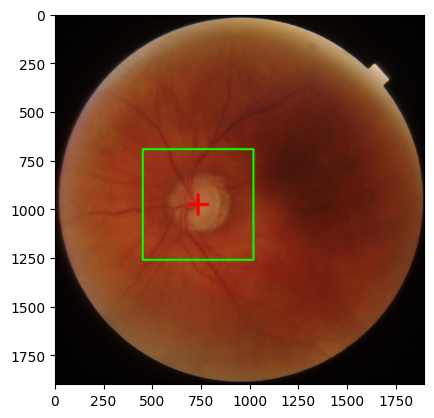

In [442]:
_maxloc = od_sobel(cv2.imread(img_path))
cropped_img = crop_od(cv2.imread(img_path), _maxloc)
plt.imshow(
    cv2.cvtColor(
        mark(cv2.imread(img_path), max_loc=_maxloc, crop_ratio=0.3), cv2.COLOR_BGR2RGB
    )
)

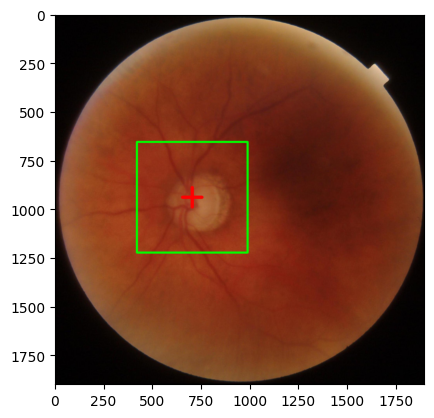

In [443]:
_maxloc = od_vessel(cv2.imread(img_path))
cropped_img = crop_od(cv2.imread(img_path), _maxloc)
plt.imshow(
    cv2.cvtColor(
        mark(cv2.imread(img_path), max_loc=_maxloc, crop_ratio=0.3), cv2.COLOR_BGR2RGB
    )
)